# Figures and tables: DAgger vs RLPD on abyss

only complete runs (with a `summary.json`) are used, so RLPD's unfinished seed 0 is left out.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
RUNS = PROJECT_ROOT / "run_results" / "stk"
FIGURES = PROJECT_ROOT / "notebooks" / "figures"
FIGURES.mkdir(exist_ok=True)

COLORS = {"DAgger": "tab:blue", "RLPD": "tab:red", "Expert": "black"}


def complete_runs(algorithm: str) -> list[Path]:
    """Run folders of one algorithm that reached their final evaluation."""
    return sorted(
        (run for run in (RUNS / algorithm).glob("seed_*") if (run / "summary.json").exists()),
        key=lambda run: json.loads((run / "metadata.json").read_text())["seed"],
    )


def seed_of(run: Path) -> int:
    return json.loads((run / "metadata.json").read_text())["seed"]

for the track, a finished lap of T steps has return `track_length / 10 + 10 - 0.1 T`,
so return and lap time are the same information. Expert's laps have a constant return.

In [2]:
expert = json.loads((RUNS / "expert" / "expert_final_evaluation.json").read_text())["summary"]
EXPERT_RETURN = expert["mean_return"]
EXPERT_LAP = expert["mean_completion_length"]
RETURN_AT_ZERO_STEPS = EXPERT_RETURN + 0.1 * EXPERT_LAP  # track_length / 10 + 10


def return_to_lap_time(value):
    """Lap time (steps) of a finished lap with this return."""
    return (RETURN_AT_ZERO_STEPS - np.asarray(value)) / 0.1


def lap_time_to_return(steps):
    return RETURN_AT_ZERO_STEPS - 0.1 * np.asarray(steps)


print(f"Expert: {EXPERT_LAP:.0f} steps, return {EXPERT_RETURN:.2f}, finish rate {expert['completion_rate']:.2f}")

Expert: 586 steps, return 77.68, finish rate 1.00


## Learning curves

* **DAgger**: one point per iteration; x = cumulative training steps (`n_labels`, one expert label per step),
  y = mean return of the 5 validation laps (seeds 5000-5004).
* **RLPD**: one point every `eval_freq` steps; y = mean return of 2 unseeded evaluation laps.
  Step 0 (before training) is dropped because the x-axis is logarithmic.

In [3]:
dagger_rows = []
for run in complete_runs("dagger"):
    with np.load(run / "dagger_history.npz") as history:
        for iteration, (steps, score) in enumerate(
            zip(history["n_labels"], history["validation_score"]), start=1
        ):
            dagger_rows.append(
                {"seed": seed_of(run), "iteration": iteration, "steps": int(steps), "return": float(score)}
            )
dagger_curve = pd.DataFrame(dagger_rows)

rlpd_rows = []
for run in complete_runs("rlpd"):
    eval_freq = json.loads((run / "metadata.json").read_text())["rlpd_config"]["eval_freq"]
    evaluations = torch.load(run / "rlpd_learning_curve.pt", weights_only=False)
    for index, evaluation in enumerate(evaluations):
        rlpd_rows.append(
            {"seed": seed_of(run), "steps": index * eval_freq, "return": evaluation["mean_return"]}
        )
rlpd_curve = pd.DataFrame(rlpd_rows)
rlpd_curve = rlpd_curve[rlpd_curve["steps"] > 0]

In [4]:
# median and interquartile range over seeds: one unfinished lap drops a return
# by about 100, so the mean and std would be dominated by single failures.
# dagger's step counts are slightly different between seeds, so it is summarised per
# iteration, at the median step count.
def quartiles(values):
    return pd.Series({"q1": values.quantile(0.25), "median": values.median(), "q3": values.quantile(0.75)})


dagger_mean = dagger_curve.groupby("iteration").apply(
    lambda group: pd.concat([pd.Series({"steps": group["steps"].median()}), quartiles(group["return"])]),
    include_groups=False,
)
rlpd_mean = rlpd_curve.groupby("steps")["return"].apply(quartiles).unstack().reset_index()
dagger_budget = dagger_mean["steps"].iloc[-1]

# how good RLPD was after using as much game time as dagger used in total
at_budget = rlpd_mean.iloc[(rlpd_mean["steps"] - dagger_budget).abs().argmin()]
print(f"DAgger budget: {dagger_budget:.0f} steps, final median return {dagger_mean['median'].iloc[-1]:.1f}")
print(f"RLPD at {at_budget['steps']:.0f} steps: median return {at_budget['median']:.1f}")
print(f"RLPD at {rlpd_mean['steps'].iloc[-1]:.0f} steps: median return {rlpd_mean['median'].iloc[-1]:.1f}")

DAgger budget: 12901 steps, final median return 78.1
RLPD at 12000 steps: median return 1.1
RLPD at 500000 steps: median return 79.5


So clearly that Dagger is much more sample efficient than rlpd, cuz with the same around 13k environment step, dagger alreadymatches the expert but rlpd has not yet learned to finished a lap. 

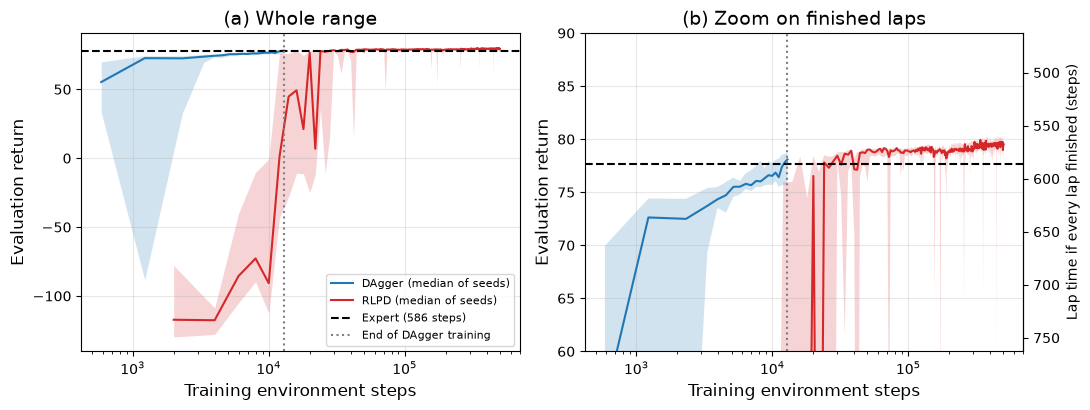

In [18]:
def draw_curves(ax):
    for name, curve in [("DAgger", dagger_mean), ("RLPD", rlpd_mean)]:
        ax.plot(curve["steps"], curve["median"], color=COLORS[name], label=f"{name} (median of seeds)")
        ax.fill_between(
            curve["steps"], curve["q1"], curve["q3"],
            color=COLORS[name], alpha=0.2, linewidth=0,
        )
    ax.axhline(EXPERT_RETURN, color=COLORS["Expert"], linestyle="--", label=f"Expert ({EXPERT_LAP:.0f} steps)")
    ax.axvline(dagger_budget, color="gray", linestyle=":", label="End of DAgger training")
    ax.set_xscale("log")
    ax.set_xlabel("Training environment steps", fontsize=12)
    ax.grid(alpha=0.3)


n_seeds = dagger_curve["seed"].nunique()
fig, (full, zoom) = plt.subplots(1, 2, figsize=(11, 4.2))

draw_curves(full)
full.set_ylabel("Evaluation return", fontsize=12)
full.set_title("(a) Whole range", fontsize=14)
full.legend(loc="lower right", fontsize=8)

draw_curves(zoom)
zoom.set_ylim(60, 90)
zoom.set_ylabel("Evaluation return", fontsize=12)
zoom.set_title("(b) Zoom on finished laps", fontsize=14)
lap_axis = zoom.secondary_yaxis("right", functions=(return_to_lap_time, lap_time_to_return))
lap_axis.set_ylabel("Lap time if every lap finished (steps)")

#fig.suptitle(f"Learning curves on abyss (median and interquartile range over {n_seeds} seeds)")
fig.tight_layout()
fig.savefig(FIGURES / "fig1_learning_curves.pdf", bbox_inches="tight")
plt.show()

A finished lap of T steps has return 136.3 − 0.1 T, so higher is faster.
The declines mean that some evaluation laps did not finish (an unfinished lap scores below −13). 

dagger's points use 5 fixed validation laps; RLPD's use 2 unseeded laps, so its curve is noisier.

## Final performance

Every run's final policy drove the same 100 evaluation laps (seeds 10000-10099).
The laps of one run are nearly identical (the game is almost deterministic for a single kart),
so the independent unit is the training seed: each run gives one lap time
(mean over its finished laps) and one finish rate.

In [6]:
final_rows = []
for algorithm, name in [("dagger", "DAgger"), ("rlpd", "RLPD")]:
    for run in complete_runs(algorithm):
        summary = json.loads((run / "summary.json").read_text())[algorithm]
        final_rows.append(
            {
                "method": name,
                "seed": seed_of(run),
                "lap_time": summary["mean_completion_length"],  # None if no lap finished
                "finish_rate": summary["completion_rate"],
            }
        )
final = pd.DataFrame(final_rows)
final.pivot(index="seed", columns="method", values=["lap_time", "finish_rate"]).round(3)

lap_time          finish_rate      
method   DAgger     RLPD      DAgger  RLPD
seed                                      
1       575.000  573.735        1.00  0.98
2       579.000  558.730        1.00  1.00
3       579.060  563.140        1.00  1.00
4       775.192  575.200        0.78  1.00
5       577.000  574.880        1.00  0.83
6       603.800  564.880        1.00  1.00
7       575.240  568.690        1.00  1.00
8       594.520  559.910        1.00  1.00
9       583.550  559.940        1.00  1.00
10      574.100  576.580        1.00  1.00
11      576.700  559.870        1.00  1.00
12      578.370  568.598        1.00  0.97

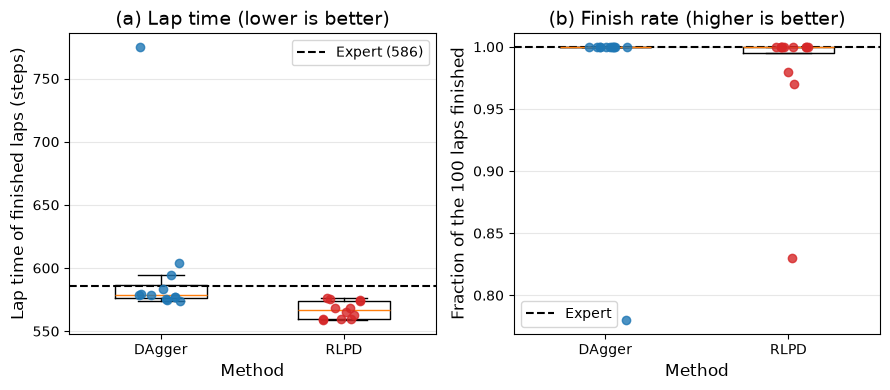

In [25]:
METHODS = ["DAgger", "RLPD"]
rng = np.random.default_rng(0)  # Only spreads the dots sideways, for readability


def draw_per_seed(ax, column):
    values = [final.loc[final["method"] == method, column].dropna() for method in METHODS]
    ax.boxplot(values, positions=range(len(METHODS)), widths=0.5, showfliers=False)
    for position, (method, points) in enumerate(zip(METHODS, values)):
        ax.scatter(
            position + rng.uniform(-0.12, 0.12, len(points)), points,
            color=COLORS[method], alpha=0.8, zorder=3,
        )
    ax.set_xticks(range(len(METHODS)), METHODS)
    ax.grid(axis="y", alpha=0.3)


fig, (lap_ax, finish_ax) = plt.subplots(1, 2, figsize=(9, 4))

draw_per_seed(lap_ax, "lap_time")
lap_ax.axhline(EXPERT_LAP, color=COLORS["Expert"], linestyle="--", label=f"Expert ({EXPERT_LAP:.0f})")
lap_ax.set_xlabel("Method", fontsize=12)
lap_ax.set_ylabel("Lap time of finished laps (steps)", fontsize=12)
lap_ax.set_title("(a) Lap time (lower is better)", fontsize=14)
lap_ax.legend(fontsize=10)

draw_per_seed(finish_ax, "finish_rate")
finish_ax.axhline(expert["completion_rate"], color=COLORS["Expert"], linestyle="--", label="Expert")
finish_ax.set_xlabel("Method", fontsize=12)
finish_ax.set_ylabel("Fraction of the 100 laps finished", fontsize=12)
finish_ax.set_title("(b) Finish rate (higher is better)", fontsize=14)
finish_ax.legend(fontsize=10)

#fig.suptitle(f"Final evaluation on 100 laps, one dot per training seed ({final['seed'].nunique()} seeds)")
fig.tight_layout()
fig.savefig(FIGURES / "fig2_final_performance.pdf", bbox_inches="tight")
plt.show()